# Phase 1: Remaining Useful Life Prediction with an ML Baseline

**Dataset:** NASA C-MAPSS turbofan engine degradation, subset FD001
**Team:** <!-- TODO: add all five team members -->
**Models:** Naive mean baseline, Elastic Net, Random Forest (engineered rolling features)

The notebook covers data quality checks and EDA, feature engineering, engine-level cross-validation, a secondary capped-target comparison, and one final evaluation on the test engines.

## 1. Problem and scope

An engine degrades in operation, and its sensor readings drift as components wear. The goal is to predict **Remaining Useful Life (RUL)**, the number of operating cycles left before failure, from the sensor history up to a given cycle. This is a regression problem.

Phase 1 covers the machine learning side: a classical baseline built on hand-engineered degradation features. Phase 2 will test whether a sequence model (LSTM) learns the same information directly from raw sensor windows.

## 2. Literature review

<!-- TODO: rewrite each entry in your own words after reading the paper, and add one or two more RUL papers. Check every citation against the original before submission. -->

- **Saxena and Goebel (2008)** introduce the C-MAPSS simulator and the FD001 to FD004 benchmark used here. The data are simulated, so the degradation is clean and the failure point is known for every training engine.
- **Breiman (2001)** introduces Random Forests, which average many decision trees trained on bootstrap samples with random feature subsets. Averaging reduces the variance of individual trees.
- **Zou and Hastie (2005)** introduce the Elastic Net, a linear model with a penalty that mixes an L1 term (sparsity) and an L2 term (shrinkage). It handles correlated features and serves here as a linear reference model.
- **Heimes (2008)** and **Babu, Zhao and Li (2016)** apply recurrent and convolutional networks to C-MAPSS RUL prediction. These motivate the sequence model in Phase 2.
- **Hochreiter and Schmidhuber (1997)** introduce the LSTM, a recurrent cell with gates that carry information across long time spans.

## 3. Data loading

The files have no header row, so the column names are set manually: `engine_id`, `cycle`, three operating settings (`op1` to `op3`), and 21 sensors (`s1` to `s21`).

The test files stop before failure. `RUL_FD001.txt` gives the true RUL at the last cycle of each test engine.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
EARLY_LATE_THRESHOLD = 50   # rows with true RUL below this are "late"
CAP = 125                   # used only in the secondary capped comparison
WINDOW = 5                  # rolling window in cycles (checked in Section 11)
BASE_N = 10                 # cycles used to define each engine's healthy baseline

sensor_cols = [f"s{i}" for i in range(1, 22)]
op_cols = ["op1", "op2", "op3"]
cols = ["engine_id", "cycle"] + op_cols + sensor_cols

train = pd.read_csv("train_FD001.txt", sep=r"\s+", header=None, names=cols)
test = pd.read_csv("test_FD001.txt", sep=r"\s+", header=None, names=cols)
rul_test = pd.read_csv("RUL_FD001.txt", sep=r"\s+", header=None, names=["RUL"])

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("RUL file shape:", rul_test.shape)
print("Train engines:", train["engine_id"].nunique(), "| Test engines:", test["engine_id"].nunique())

Train shape: (20631, 26)
Test shape: (13096, 26)
RUL file shape: (100, 1)
Train engines: 100 | Test engines: 100


## 4. Target: remaining useful life

For each training row, RUL = (last cycle of that engine) minus (current cycle). The last row of every training engine therefore has RUL = 0.

The main model uses **uncapped** RUL. The test target is the value in `RUL_FD001.txt`, which applies only to each test engine's last cycle.

In [2]:
max_cycle = train.groupby("engine_id")["cycle"].transform("max")
train["RUL"] = max_cycle - train["cycle"]

print("Min RUL per engine (should all be 0):", train.groupby("engine_id")["RUL"].min().unique())
print("Max RUL (uncapped):", train["RUL"].max())

Min RUL per engine (should all be 0): [0]
Max RUL (uncapped): 361


## 5. Data quality checks

We check for missing values, duplicate rows, data types, and cycle continuity. The test set gets the same checks.

In [3]:
print("Missing values | train:", train.isna().sum().sum(),
      "| test:", test.isna().sum().sum(),
      "| RUL file:", rul_test.isna().sum().sum())
print("Duplicate rows | train:", train.duplicated().sum(), "| test:", test.duplicated().sum())
print("Duplicate (engine_id, cycle) pairs | train:", train.duplicated(["engine_id", "cycle"]).sum(),
      "| test:", test.duplicated(["engine_id", "cycle"]).sum())

print("\nColumn data types:")
print(train.dtypes.value_counts().to_string())

for name, df in [("train", train), ("test", test)]:
    c = df.groupby("engine_id")["cycle"].agg(["min", "max", "count"])
    ok = ((c["min"] == 1) & (c["max"] == c["count"])).all()
    print(f"{name}: every engine starts at cycle 1 with no gaps:", ok)

print("RUL file has one row per test engine:", len(rul_test) == test["engine_id"].nunique())

Missing values | train: 0 | test: 0 | RUL file: 0
Duplicate rows | train: 0 | test: 0
Duplicate (engine_id, cycle) pairs | train: 0 | test: 0

Column data types:
float64    22
int64       5
train: every engine starts at cycle 1 with no gaps: True
test: every engine starts at cycle 1 with no gaps: True
RUL file has one row per test engine: True


## 6. Exploratory data analysis

The EDA answers four questions: how long engines last, what the target looks like, which sensors carry a degradation signal, and which columns can be ignored.

In [4]:
eda_table = pd.DataFrame({
    "std": train[op_cols + sensor_cols].std(),
    "unique values": train[op_cols + sensor_cols].nunique(),
    "min": train[op_cols + sensor_cols].min(),
    "max": train[op_cols + sensor_cols].max(),
})
print(eda_table.round(6).to_string())

           std  unique values        min        max
op1   0.002187            158    -0.0087     0.0087
op2   0.000293             13    -0.0006     0.0006
op3   0.000000              1   100.0000   100.0000
s1    0.000000              1   518.6700   518.6700
s2    0.500053            310   641.2100   644.5300
s3    6.131150           3012  1571.0400  1616.9100
s4    9.000605           4051  1382.2500  1441.4900
s5    0.000000              1    14.6200    14.6200
s6    0.001389              2    21.6000    21.6100
s7    0.885092            513   549.8500   556.0600
s8    0.070985             53  2387.9000  2388.5600
s9   22.082880           6403  9021.7300  9244.5900
s10   0.000000              1     1.3000     1.3000
s11   0.267087            159    46.8500    48.5300
s12   0.737553            427   518.6900   523.3800
s13   0.071919             56  2387.8800  2388.5600
s14  19.076176           6078  8099.9400  8293.7200
s15   0.037505           1918     8.3249     8.5848
s16   0.0000

**Operating settings.** `op3` takes a single value across the whole dataset, and `op1` and `op2` vary only by tiny amounts around fixed points. FD001 has one operating condition, so these settings describe sensor noise, not a change in regime. They are left out of the feature set, which is also why the regime feature from the project brief is not needed here.

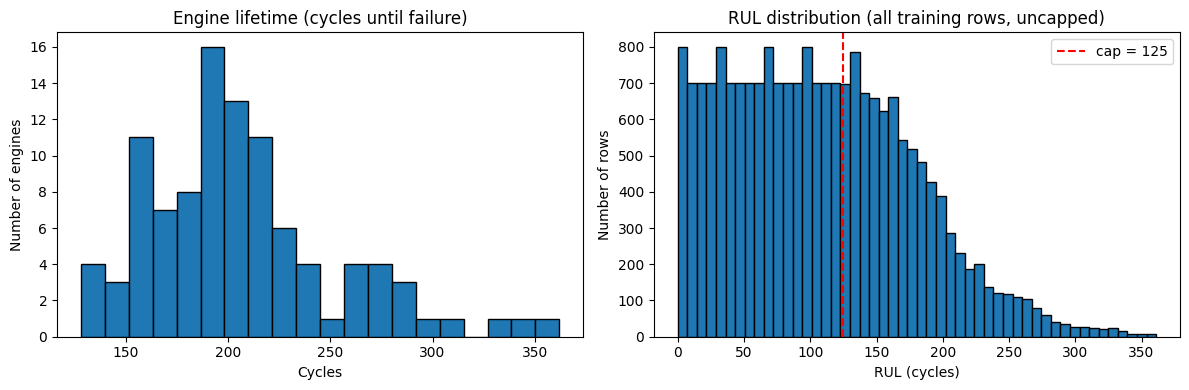

count    100.0
mean     206.3
std       46.3
min      128.0
25%      177.0
50%      199.0
75%      229.2
max      362.0
Share of rows with RUL above the cap: 0.389


In [5]:
lifecycle = train.groupby("engine_id").size()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(lifecycle, bins=20, edgecolor="black")
axes[0].set_title("Engine lifetime (cycles until failure)")
axes[0].set_xlabel("Cycles")
axes[0].set_ylabel("Number of engines")

axes[1].hist(train["RUL"], bins=50, edgecolor="black")
axes[1].axvline(CAP, color="red", linestyle="--", label=f"cap = {CAP}")
axes[1].set_title("RUL distribution (all training rows, uncapped)")
axes[1].set_xlabel("RUL (cycles)")
axes[1].set_ylabel("Number of rows")
axes[1].legend()
plt.tight_layout()
plt.show()

print(lifecycle.describe().round(1).to_string())
print("Share of rows with RUL above the cap:", round((train["RUL"] > CAP).mean(), 3))

Engine lifetimes vary a lot, so the training rows are not evenly spread over the life of an engine. Most rows sit at high RUL, and only a smaller share fall in the last 50 cycles. This imbalance is one reason the early stage is harder to predict in later sections. The red line marks the cap of 125, where many papers start clipping the target.

<!-- TODO: check these statements against your own plots and edit to match. -->

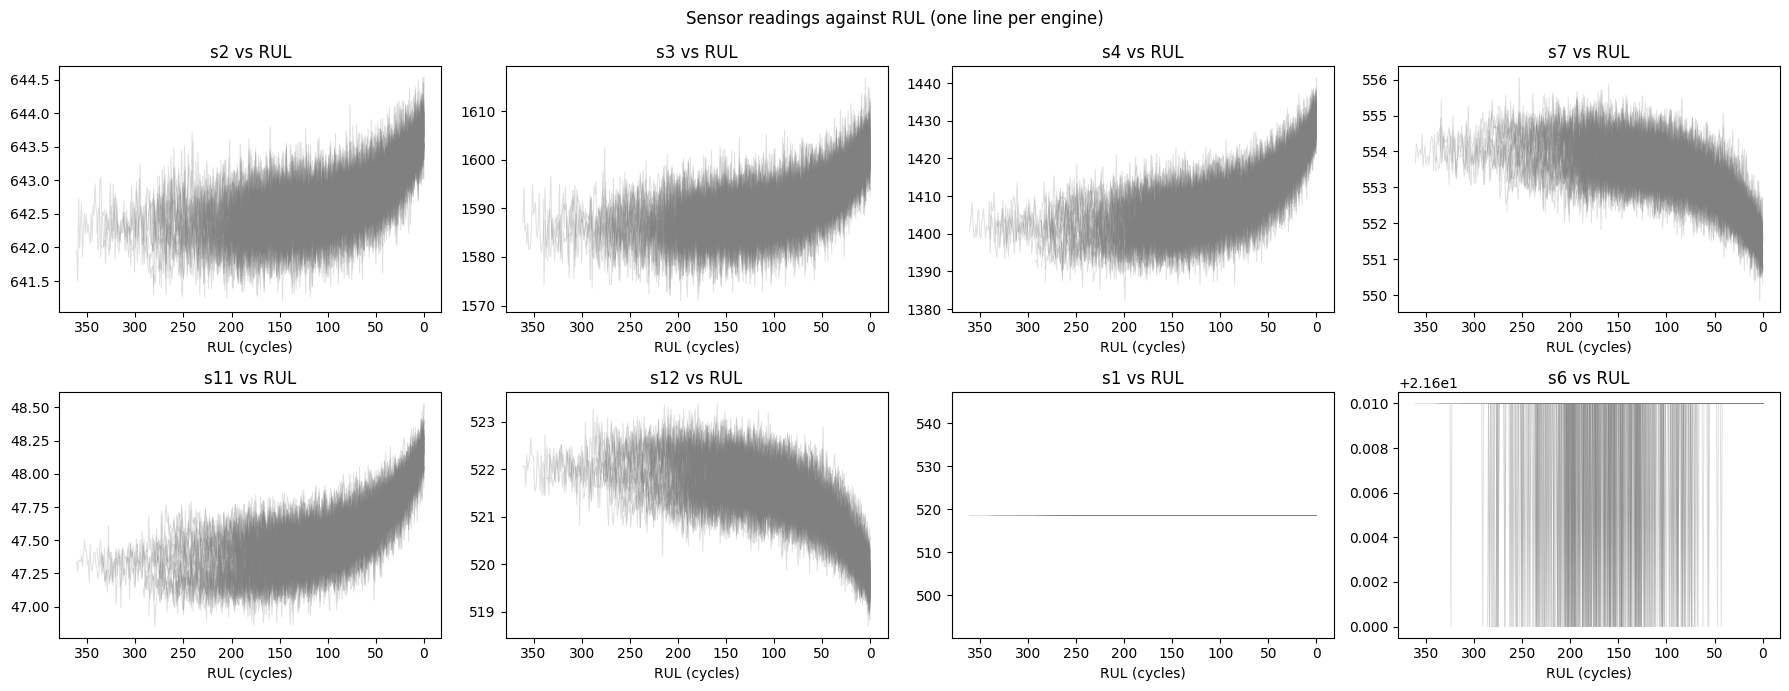

In [6]:
show = ["s2", "s3", "s4", "s7", "s11", "s12", "s1", "s6"]

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, s in zip(axes.ravel(), show):
    for _, d in train.groupby("engine_id"):
        ax.plot(d["RUL"], d[s], color="grey", alpha=0.25, linewidth=0.7)
    ax.set_title(f"{s} vs RUL")
    ax.set_xlabel("RUL (cycles)")
    ax.invert_xaxis()  # time runs left to right, toward failure
plt.suptitle("Sensor readings against RUL (one line per engine)")
plt.tight_layout()
plt.show()

Sensors `s2`, `s3`, `s4`, `s7`, `s11`, and `s12` change over the life of each engine, and the change accelerates or becomes clearer as RUL falls. Engines follow different paths, so the same reading can mean different things for different engines. That is why the features look at the current level, the recent change, and the drift from the engine's own start.

Sensors `s1` and `s6` are essentially flat across the whole life. They carry no degradation signal, so they are dropped in Section 7.

<!-- TODO: check these statements against your own plots and edit to match. -->

In [7]:
corr = train[sensor_cols + ["cycle"]].corrwith(train["RUL"], method="spearman")
print("Spearman correlation with RUL (NaN means a constant column):")
print(corr.sort_values().round(3).to_string())

Spearman correlation with RUL (NaN means a constant column):
cycle   -0.787
s11     -0.718
s4      -0.702
s15     -0.666
s17     -0.629
s2      -0.629
s3      -0.606
s8      -0.574
s13     -0.573
s9      -0.322
s14     -0.202
s6      -0.128
s20      0.653
s21      0.657
s7       0.679
s12      0.693
s1         NaN
s5         NaN
s10        NaN
s16        NaN
s18        NaN
s19        NaN


/usr/local/lib/python3.13/dist-packages/pandas/core/nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


Rank correlation is a quick screen for which sensors move with RUL. Constant sensors return NaN. The screen is only a rough guide, because it mixes differences between engines with differences within an engine. The model is trained on the full feature set, not on correlation alone.

## 7. Sensor selection

**Rule:** drop a sensor if its standard deviation on the training data is below 0.01. The rule uses training readings only and no labels, so it does not leak test information.

This removes the constant or near-constant sensors (`s1`, `s5`, `s6`, `s10`, `s16`, `s18`, `s19`) and keeps `s15` (standard deviation about 0.04), which varies enough to be informative. The gap between `s6` (about 0.0014) and `s15` (about 0.0375) is wide, so any threshold between roughly 0.002 and 0.03 gives the same set of sensors.

In [8]:
train_std = train[sensor_cols].std()
drop_sensors = train_std[train_std < 0.01].index.tolist()
keep_sensors = [s for s in sensor_cols if s not in drop_sensors]

print("Dropped (std < 0.01):", drop_sensors)
print("Kept:", keep_sensors)
print("Number kept:", len(keep_sensors))

Dropped (std < 0.01): ['s1', 's5', 's6', 's10', 's16', 's18', 's19']
Kept: ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']
Number kept: 14


## 8. Feature engineering

A Random Forest sees one row at a time, so it cannot read an engine's history directly. We add history-based features for each kept sensor:

- **Rolling mean** over the last `WINDOW` cycles. It smooths measurement noise.
- **Rolling slope** over the last `WINDOW` cycles, in its two-point form: (value now minus value `WINDOW - 1` cycles ago) divided by `WINDOW - 1`. It measures how fast the sensor is moving.
- **Health:** the reading minus the engine's own mean over its first `BASE_N` cycles. It measures how far the sensor has drifted from the engine's healthy start.

**Causality.** Every feature at cycle t uses only cycles up to t of the same engine. The health baseline is used only from cycle `BASE_N` onward. Before that, health is set to 0, meaning no drift has been observed yet. This avoids using future cycles in the early rows. Features are computed per engine, so no information crosses between engines.

Together with `cycle` and the 14 raw sensors, this gives 57 features: 1 + 14 + 14 × 3.

In [9]:
def build_features(df, w=WINDOW, base_n=BASE_N):
    """Per-engine features. Each row uses only its own engine's current and past cycles."""
    df = df.sort_values(["engine_id", "cycle"]).copy()
    g = df.groupby("engine_id")
    new_cols = []
    for s in keep_sensors:
        df[f"{s}_mean"] = g[s].transform(lambda x: x.rolling(w, min_periods=1).mean())
        df[f"{s}_slope"] = g[s].transform(lambda x: (x - x.shift(w - 1)) / (w - 1)).fillna(0)
        baseline = g[s].transform(lambda x: x.iloc[:base_n].mean())
        health = df[s] - baseline
        df[f"{s}_health"] = health.where(df["cycle"] >= base_n, 0.0)
        new_cols += [f"{s}_mean", f"{s}_slope", f"{s}_health"]
    feature_cols = ["cycle"] + keep_sensors + new_cols
    return df, feature_cols

full_f, feature_cols = build_features(train)
print("Number of features:", len(feature_cols))
print("Feature matrix shape:", full_f[feature_cols].shape)
print("Any NaNs:", full_f[feature_cols].isna().sum().sum())

Number of features: 57
Feature matrix shape: (20631, 57)
Any NaNs: 0


## 9. Theoretical background

- **Random Forest and bagging.** A Random Forest fits many decision trees. Each tree sees a bootstrap sample (rows drawn with replacement) and tries only a random subset of features at each split. Individual deep trees overfit, but their errors partly cancel when averaged. `min_samples_leaf=5` stops a leaf from memorising a handful of rows.
- **Elastic Net.** A linear model with a penalty that mixes an L1 term, which can set coefficients exactly to zero, and an L2 term, which keeps correlated features stable. Features are standardised first so the penalty treats them equally. It gives a linear reference point for the tree model.
- **RMSE and MAE.** Both are in cycles. MAE is the average absolute error. RMSE squares errors before averaging, so one large miss counts for more. Reporting both shows whether a few large errors dominate the score.
- **Why group splits.** Rows from the same engine are strongly correlated. Splitting by row would put near-identical rows in both training and validation and inflate the scores. `GroupKFold` keeps every engine in exactly one fold.
- **Why the test set is used once.** Using the test set to choose settings would make its score optimistic. Here the test set is scored once, by models trained on all training engines.
- **Scaling inside the pipeline.** The `StandardScaler` sits inside the Elastic Net pipeline, so it is fitted only on each training fold. Fitting it on all data first would leak fold statistics into the evaluation.

## 10. Evaluation protocol

All model comparisons use **5-fold `GroupKFold` on engine ID**, applied to all 100 training engines. Each fold holds out 20 engines, which are predicted by a model trained on the other 80. Across the five folds, every training engine is predicted exactly once, out of fold. We report the mean and standard deviation of each metric across folds.

The metrics are RMSE, MAE, and MAE split into early (true RUL at least 50) and late (true RUL below 50). The stage uses the true RUL, so it describes where the model is accurate, not what it can see. The test set stays untouched until Section 15.

In [10]:
gkf = GroupKFold(n_splits=5)


def metrics(y_true, y_pred):
    err = np.abs(y_true - y_pred)
    late = y_true < EARLY_LATE_THRESHOLD
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "MAE early": err[~late].mean(),
        "MAE late": err[late].mean(),
    }


def evaluate_cv(make_model, df, feats, target_train=None):
    """Group-wise 5-fold CV. Returns out-of-fold predictions and per-fold metrics.
    target_train optionally transforms the training target (for example, capping).
    Scoring always uses the true, uncapped RUL."""
    X = df[feats].values
    y = df["RUL"].values
    groups = df["engine_id"].values
    oof = np.zeros(len(df))
    fold_scores = []
    for tr_idx, te_idx in gkf.split(X, y, groups):
        y_fit = y[tr_idx] if target_train is None else target_train(y[tr_idx])
        model = make_model()
        model.fit(X[tr_idx], y_fit)
        oof[te_idx] = model.predict(X[te_idx])
        fold_scores.append(metrics(y[te_idx], oof[te_idx]))
    return oof, pd.DataFrame(fold_scores)


def summarize(fold_df):
    return pd.Series({c: f"{fold_df[c].mean():.2f} ± {fold_df[c].std():.2f}" for c in fold_df.columns})

## 11. Window size check

The 5-cycle window was a choice, not a result. This section compares windows of 3, 5, and 10 cycles with the same Random Forest on the same folds. It uses 100 trees to keep runtime down.

Read the table this way: choose the window with the lowest CV RMSE. If two windows differ by less than the fold standard deviation, prefer the simpler, smaller one. If your result picks a different window, change `WINDOW` in Section 3 and re-run the notebook from the top.

In [11]:
def cv_rf_for_window(w):
    df_w, feats_w = build_features(train, w=w)

    def make():
        return RandomForestRegressor(n_estimators=100, min_samples_leaf=5,
                                     random_state=RANDOM_STATE, n_jobs=-1)

    _, folds = evaluate_cv(make, df_w, feats_w)
    return folds.mean()


window_sweep = pd.DataFrame({w: cv_rf_for_window(w) for w in [3, 5, 10]}).T
window_sweep.index.name = "window"
print(window_sweep.round(2).to_string())

         RMSE    MAE  MAE early  MAE late
window                                   
3       34.40  22.59      28.13      5.29
5       34.82  22.85      28.54      5.05
10      36.28  23.76      29.76      5.00


## 12. Model comparison (cross-validation)

Three models are compared on identical features and folds:

- **Naive baseline:** always predicts the mean RUL of the training fold. A useful model has to beat this.
- **Elastic Net:** a linear model on standardised features, with fixed settings (`alpha = 1.0`, `l1_ratio = 0.5`).
- **Random Forest:** 200 trees with `min_samples_leaf = 5`.

The Elastic Net and Random Forest settings are fixed and were not tuned. The comparison is fair because every model sees the same data, but absolute scores might improve with a tuning search run inside the cross-validation.

In [12]:
models = {
    "Naive (mean RUL)": lambda: DummyRegressor(strategy="mean"),
    "Elastic Net": lambda: make_pipeline(StandardScaler(),
                                         ElasticNet(alpha=1.0, l1_ratio=0.5, max_iter=10000)),
    "Random Forest": lambda: RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                                                   random_state=RANDOM_STATE, n_jobs=-1),
}

oof_preds, cv_folds = {}, {}
for name, make in models.items():
    oof_preds[name], cv_folds[name] = evaluate_cv(make, full_f, feature_cols)

cv_table = pd.DataFrame({name: summarize(f) for name, f in cv_folds.items()}).T
print("5-fold GroupKFold CV on 100 training engines (mean ± std across folds)")
print(cv_table.to_string())

5-fold GroupKFold CV on 100 training engines (mean ± std across folds)
                          RMSE           MAE     MAE early      MAE late
Naive (mean RUL)  68.87 ± 1.32  56.86 ± 0.51  48.40 ± 0.71  83.31 ± 0.12
Elastic Net       40.04 ± 2.98  30.63 ± 1.56  32.96 ± 2.19  23.35 ± 1.21
Random Forest     34.78 ± 1.97  22.79 ± 0.91  28.47 ± 1.11   5.04 ± 0.34


## 13. Error analysis

The out-of-fold predictions cover all 20,631 training rows, so this analysis is based on far more rows than the single validation split used in the first version of this notebook.

The left plot shows how close predictions are to the true RUL. The right plot shows mean absolute error for each 25-cycle range of true RUL.

<!-- TODO: check these statements against your own plots and edit to match. -->

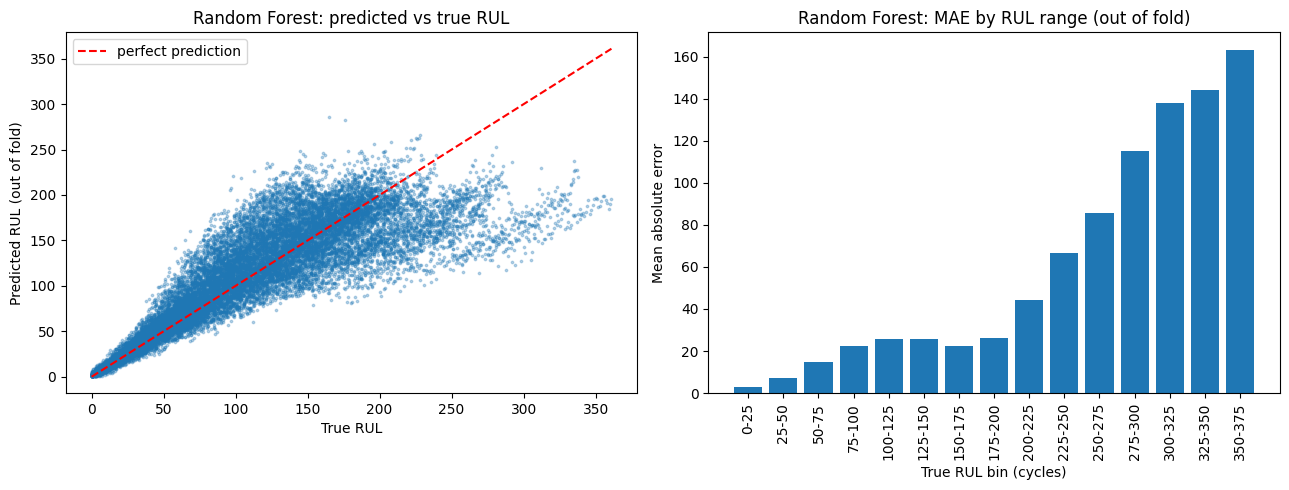

In [13]:
y_all = full_f["RUL"].values
oof_rf = oof_preds["Random Forest"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_all, oof_rf, s=3, alpha=0.3)
axes[0].plot([0, y_all.max()], [0, y_all.max()], "r--", label="perfect prediction")
axes[0].set_xlabel("True RUL")
axes[0].set_ylabel("Predicted RUL (out of fold)")
axes[0].set_title("Random Forest: predicted vs true RUL")
axes[0].legend()

abs_err = pd.Series(np.abs(y_all - oof_rf))
bins = pd.cut(pd.Series(y_all), bins=range(0, int(y_all.max()) + 25, 25))
err_by_bin = abs_err.groupby(bins, observed=True).mean()
axes[1].bar(range(len(err_by_bin)), err_by_bin.values)
axes[1].set_xticks(range(len(err_by_bin)))
axes[1].set_xticklabels([f"{int(b.left)}-{int(b.right)}" for b in err_by_bin.index], rotation=90)
axes[1].set_xlabel("True RUL bin (cycles)")
axes[1].set_ylabel("Mean absolute error")
axes[1].set_title("Random Forest: MAE by RUL range (out of fold)")

plt.tight_layout()
plt.show()

## 14. Secondary comparison: capped RUL

Many papers cap the training target at 125 cycles, because all early-life engines look healthy and their exact remaining life is hard to see. The project does not ask for a cap, so the main model stays uncapped. This section tests a capped model fairly:

- The capped model is trained on `min(RUL, 125)`.
- Both models are scored on the **uncapped** RUL, which is the project's target.

Scoring the capped model against capped truth would favour it by construction, so that comparison is not used to make the decision.

In [14]:
oof_cap, cap_folds = evaluate_cv(
    models["Random Forest"], full_f, feature_cols,
    target_train=lambda y: np.minimum(y, CAP),
)

cap_cmp = pd.DataFrame({
    "RF uncapped": summarize(cv_folds["Random Forest"]),
    f"RF capped at {CAP}": summarize(cap_folds),
}).T
print("Both scored on uncapped RUL, 5-fold GroupKFold CV:")
print(cap_cmp.to_string())

Both scored on uncapped RUL, 5-fold GroupKFold CV:
                          RMSE           MAE     MAE early     MAE late
RF uncapped       34.78 ± 1.97  22.79 ± 0.91  28.47 ± 1.11  5.04 ± 0.34
RF capped at 125  46.40 ± 2.11  28.90 ± 0.81  36.55 ± 1.11  4.97 ± 0.29


## 15. Final models and test set

The test set is used once. The final models are trained on all 100 training engines with the same features and settings. Each test engine is scored at its last cycle, which is the only cycle with a given true RUL.

In [15]:
final_models = {name: make().fit(full_f[feature_cols].values, y_all) for name, make in models.items()}

test_f, _ = build_features(test)
last = test_f.groupby("engine_id").tail(1).sort_values("engine_id").reset_index(drop=True)
y_test = rul_test["RUL"].values

print("Test engines scored:", len(last),
      "| last-cycle range:", last["cycle"].min(), "to", last["cycle"].max())

test_results, rf_test_pred = {}, None
for name, m in final_models.items():
    pred = m.predict(last[feature_cols].values)
    test_results[name] = metrics(y_test, pred)
    if name == "Random Forest":
        rf_test_pred = pred

test_table = pd.DataFrame(test_results).T.round(2)
print("Test set, 100 engines (one row per engine at its last cycle):")
print(test_table.to_string())

Test engines scored: 100 | last-cycle range: 31 to 303
Test set, 100 engines (one row per engine at its last cycle):
                   RMSE    MAE  MAE early  MAE late
Naive (mean RUL)  52.62  40.88      21.44     86.24
Elastic Net       27.98  23.68      25.02     20.55
Random Forest     23.34  15.58      20.54      4.02


In [16]:
stage_test = np.where(y_test < EARLY_LATE_THRESHOLD, "late", "early")
rf_err = np.abs(y_test - rf_test_pred)
print("Random Forest test error by stage:")
print(pd.Series(rf_err).groupby(stage_test).agg(["mean", "count"]).round(2).to_string())

importance = pd.Series(final_models["Random Forest"].feature_importances_, index=feature_cols)
print("\nTop 10 Random Forest features (impurity-based importance):")
print(importance.sort_values(ascending=False).head(10).round(3).to_string())

Random Forest test error by stage:
        mean  count
early  20.54     70
late    4.02     30

Top 10 Random Forest features (impurity-based importance):
cycle         0.559
s4_mean       0.088
s15_mean      0.048
s11_mean      0.042
s11_health    0.038
s14_mean      0.017
s9_health     0.016
s12_mean      0.016
s9_mean       0.012
s21_mean      0.009


## 16. Results

Model choice is based on the cross-validation table in Section 12, because it uses all 100 training engines and all their rows. The test table in Section 15 is the final held-out check. The table below collects both.

In [17]:
print("| Model | Data | RMSE | MAE | MAE early | MAE late |")
print("|---|---|---|---|---|---|")
for name in models:
    r = cv_folds[name].mean()
    print(f"| {name} | CV mean (5 folds) | {r['RMSE']:.2f} | {r['MAE']:.2f} | "
          f"{r['MAE early']:.2f} | {r['MAE late']:.2f} |")
for name in models:
    r = test_results[name]
    print(f"| {name} | Test (100 engines) | {r['RMSE']:.2f} | {r['MAE']:.2f} | "
          f"{r['MAE early']:.2f} | {r['MAE late']:.2f} |")

| Model | Data | RMSE | MAE | MAE early | MAE late |
|---|---|---|---|---|---|
| Naive (mean RUL) | CV mean (5 folds) | 68.87 | 56.86 | 48.40 | 83.31 |
| Elastic Net | CV mean (5 folds) | 40.04 | 30.63 | 32.96 | 23.35 |
| Random Forest | CV mean (5 folds) | 34.78 | 22.79 | 28.47 | 5.04 |
| Naive (mean RUL) | Test (100 engines) | 52.62 | 40.88 | 21.44 | 86.24 |
| Elastic Net | Test (100 engines) | 27.98 | 23.68 | 25.02 | 20.55 |
| Random Forest | Test (100 engines) | 23.34 | 15.58 | 20.54 | 4.02 |


**Findings** (check each statement against the printed tables before submitting)

- The naive baseline sets the floor. Each learned model should beat it on both CV and test.
- Compare Elastic Net and Random Forest on the same rows. A large gap means the relationship between features and RUL is non-linear, which tree models capture and a linear model cannot.
- Error is larger early in life than late, in both CV and test. The late group is smaller, and the features change more clearly close to failure.
- The capped model (Section 14) is judged on uncapped RUL. The main model stays uncapped unless the capped version is better on that target.
- CV and test should agree in direction. The test set has only 100 engines, each scored at one cycle, so if the two disagree, weight the CV mean more heavily.

**Limitations**

- Model settings are fixed and not tuned. Elastic Net and Random Forest could improve with a search run inside the cross-validation.
- The window size was chosen by CV on the same engines used for the model comparison, so the CV scores are slightly optimistic. The test set is the unbiased check.
- The baseline length (`BASE_N = 10`) and the late threshold (RUL below 50) were set by hand and not tested.
- The two-point slope is simple. A fitted slope over the window could describe the trend better.
- The test score is one cycle per engine across 100 engines, so it has high variance.
- Only FD001 is used. FD002 to FD004 would test whether the features still work when operating conditions change.
- Fixed rolling windows may miss long-term degradation trends. This is the gap the LSTM in Phase 2 will test, on the same split.